In [1]:
print("AI Data Analyst Project - Python Environment Ready!")

AI Data Analyst Project - Python Environment Ready!


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

print("All libraries imported successfully!")

All libraries imported successfully!


In [6]:
file_path = Path("../Dataset/retail_sales_validated_final.xlsx")

if file_path.exists():
    print("Dataset found successfully!")
else:
    print("Dataset not found. Available files:")
    print(list(Path("../Dataset").glob("*")))

Dataset found successfully!


In [13]:
df = pd.read_excel(
    file_path,
    sheet_name="validated_transactions"
)

print("Dataset loaded successfully!")
print("Rows and Columns:", df.shape)

display(df.head())

Dataset loaded successfully!
Rows and Columns: (124754, 19)


,Transaction_ID,Order_Date,Customer_ID,Customer_Segment,Region,State,City,Sales_Channel,Category,Product,Quantity,Unit_Price_INR,Discount_Rate,Sales_Amount_INR,Unit_Cost_INR,Total_Cost_INR,Profit_INR,Payment_Method,Order_Status
0,TXN0000001,2024-02-27,CUST03658,Consumer,South,Andhra Pradesh,Visakhapatnam,Marketplace,Fashion,Jeans,4,1399,0.15,4756.60,620,2480,2276.60,UPI,Completed
1,TXN0000002,2025-05-10,CUST01536,Consumer,Central,Madhya Pradesh,Bhopal,Online,Electronics,Wireless Mouse,1,599,0.15,509.15,280,280,229.15,Net Banking,Completed
2,TXN0000003,2025-02-22,CUST04558,Consumer,Central,Madhya Pradesh,Bhopal,Online,Home & Kitchen,Cookware Set,2,2199,0.15,3738.30,1320,2640,1098.30,Cash,Completed
3,TXN0000004,2024-10-07,CUST06225,Consumer,North,Uttar Pradesh,Kanpur,Store,Electronics,Wireless Mouse,2,599,0.10,1078.20,280,560,518.20,Debit Card,Completed
4,TXN0000005,2024-10-04,CUST04804,Corporate,South,Karnataka,Bengaluru,Marketplace,Beauty,Face Wash,1,249,0.00,249.00,90,90,159.00,Debit Card,Completed


In [ ]:
# 1. Dataset information


In [7]:
print("DATASET INFORMATION")
print("-------------------")
df.info()

DATASET INFORMATION
-------------------


NameError: name 'df' is not defined

In [ ]:
# 2. Check missing values

In [11]:
print("\nMISSING VALUES")
print("--------------")
print(df.isnull().sum())


MISSING VALUES
--------------
Transaction_ID      0
Order_Date          0
Customer_ID         0
Customer_Segment    0
Region              0
State               0
City                0
Sales_Channel       0
Category            0
Product             0
Quantity            0
Unit_Price_INR      0
Discount_Rate       0
Sales_Amount_INR    0
Unit_Cost_INR       0
Total_Cost_INR      0
Profit_INR          0
Payment_Method      0
Order_Status        0
dtype: int64


In [ ]:
# 3. Check duplicate records

In [8]:
print("\nDUPLICATE CHECK")
print("---------------")
print("Duplicate rows:", df.duplicated().sum())


DUPLICATE CHECK
---------------
Duplicate rows: 0


In [ ]:
# 4. Check duplicate Transaction IDs

In [9]:
print("Duplicate Transaction IDs:",
      df["Transaction_ID"].duplicated().sum())

Duplicate Transaction IDs: 0


In [ ]:
# Calculate business KPIs

In [10]:

total_revenue = df["Sales_Amount_INR"].sum()
total_profit = df["Profit_INR"].sum()
total_cost = df["Total_Cost_INR"].sum()
total_transactions = df["Transaction_ID"].nunique()
total_units = df["Quantity"].sum()

average_transaction_value = total_revenue / total_transactions
profit_margin = (total_profit / total_revenue) * 100

# Display KPI results

print("RETAIL SALES BUSINESS KPI ANALYSIS")
print("----------------------------------")

print(f"Total Revenue: ₹{total_revenue:,.2f}")
print(f"Total Profit: ₹{total_profit:,.2f}")
print(f"Total Cost: ₹{total_cost:,.2f}")
print(f"Total Transactions: {total_transactions:,}")
print(f"Total Units Sold: {total_units:,}")
print(f"Average Transaction Value: ₹{average_transaction_value:,.2f}")
print(f"Profit Margin: {profit_margin:.2f}%")

RETAIL SALES BUSINESS KPI ANALYSIS
----------------------------------
Total Revenue: ₹215,489,969.15
Total Profit: ₹100,662,489.15
Total Cost: ₹114,827,480.00
Total Transactions: 124,754
Total Units Sold: 268,592
Average Transaction Value: ₹1,727.32
Profit Margin: 46.71%


In [ ]:
#Analyze numerical columns

In [14]:
df[[
    "Quantity",
    "Unit_Price_INR",
    "Unit_Cost_INR",
    "Discount_Rate",
    "Sales_Amount_INR",
    "Total_Cost_INR",
    "Profit_INR"
]].describe().round(2)

,Quantity,Unit_Price_INR,Unit_Cost_INR,Discount_Rate,Sales_Amount_INR,Total_Cost_INR,Profit_INR
count,124754.00,124754.00,124754.00,124754.00,124754.00,124754.00,124754.00
mean,2.15,848.36,426.05,0.06,1727.32,920.43,806.89
std,1.34,737.00,438.87,0.06,2082.43,1257.28,887.09
min,1.00,149.00,70.00,0.00,119.20,70.00,6.20
25%,1.00,349.00,145.00,0.00,474.05,240.00,239.10
50%,2.00,499.00,240.00,0.05,998.00,465.00,528.10
75%,3.00,1199.00,520.00,0.10,2158.20,1080.00,1049.00
max,6.00,2899.00,1850.00,0.20,17394.00,11100.00,7314.00


In [ ]:
#Monthly Revenue Trend (2024 vs 2025)

In [12]:
# Convert Order_Date into datetime format
df["Order_Date"] = pd.to_datetime(df["Order_Date"])

# Extract year and month
df["Year"] = df["Order_Date"].dt.year
df["Month_Number"] = df["Order_Date"].dt.month
df["Month_Name"] = df["Order_Date"].dt.strftime("%b")

# Calculate monthly revenue
monthly_revenue = (
    df.groupby(["Year", "Month_Number", "Month_Name"])["Sales_Amount_INR"]
    .sum()
    .reset_index()
)

display(monthly_revenue.head(15))

,Year,Month_Number,Month_Name,Sales_Amount_INR
0,2024,1,Jan,10632446.05
1,2024,2,Feb,9465234.70
2,2024,3,Mar,10757031.55
3,2024,4,Apr,10051647.15
4,2024,5,May,10430423.15
5,2024,6,Jun,10137763.95
6,2024,7,Jul,10422234.30
7,2024,8,Aug,10256779.80
8,2024,9,Sep,10377728.80
9,2024,10,Oct,10387377.75


In [ ]:
# Comparision chart

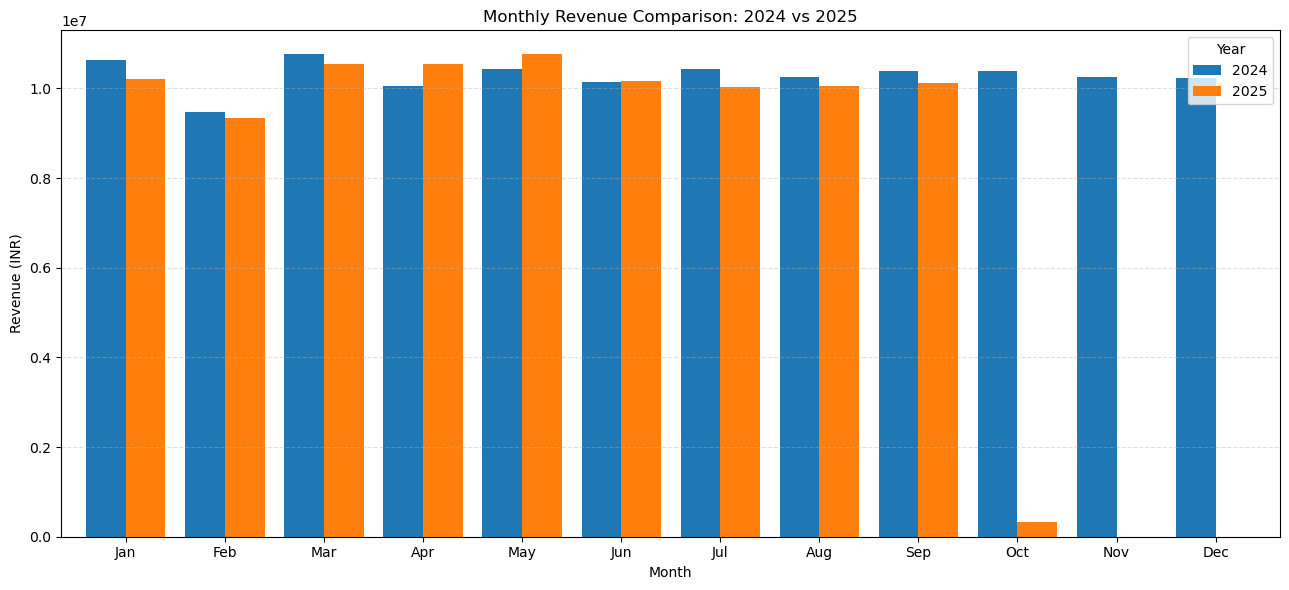

In [13]:
# Prepare data for year-wise monthly comparison
monthly_pivot = monthly_revenue.pivot(
    index="Month_Number",
    columns="Year",
    values="Sales_Amount_INR"
)

# Month labels
month_labels = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

monthly_pivot.index = [
    month_labels[i - 1] for i in monthly_pivot.index
]

# Create chart
monthly_pivot.plot(
    kind="bar",
    figsize=(13, 6),
    width=0.8
)

plt.title("Monthly Revenue Comparison: 2024 vs 2025")
plt.xlabel("Month")
plt.ylabel("Revenue (INR)")
plt.xticks(rotation=0)
plt.legend(title="Year")
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

In [ ]:
## Revenue and Profit Analysis

In [14]:
dimensions = [
    "Category",
    "Region",
    "Customer_Segment",
    "Sales_Channel"
]

for column in dimensions:
    print(f"\n{'=' * 50}")
    print(f"PERFORMANCE BY {column.upper()}")
    print("=" * 50)

    summary = (
        df.groupby(column)
        .agg(
            Total_Revenue=("Sales_Amount_INR", "sum"),
            Total_Profit=("Profit_INR", "sum"),
            Total_Transactions=("Transaction_ID", "nunique"),
            Units_Sold=("Quantity", "sum")
        )
        .sort_values("Total_Revenue", ascending=False)
    )

    display(summary.round(2))


PERFORMANCE BY CATEGORY


,Total_Revenue,Total_Profit,Total_Transactions,Units_Sold
Category,,,,
Home & Kitchen,68781548.75,26989578.75,24608,53280
Fashion,63284344.30,32537784.30,25028,54568
Electronics,45013625.20,22866885.20,24682,52798
Beauty,24988788.85,14206703.85,24741,53195
Grocery,12512098.80,3645838.80,25195,53685
home & kitchen,362423.90,139093.90,110,244
fashion,221790.40,115370.40,102,206
electronics,189010.20,95800.20,98,214
beauty,90146.55,51441.55,99,199



PERFORMANCE BY REGION


,Total_Revenue,Total_Profit,Total_Transactions,Units_Sold
Region,,,,
North,43263437.95,20206247.95,24650,53326
East,43128971.95,20140501.95,24924,53613
South,42975719.75,20072919.75,24911,53729
Central,42650128.30,19905073.30,24826,53205
West,42616830.40,19931185.40,24943,53634
central,192051.50,86746.50,104,225
west,191692.20,91547.20,111,233
east,174666.90,85571.90,86,195
north,153888.70,74943.70,102,215



PERFORMANCE BY CUSTOMER_SEGMENT


,Total_Revenue,Total_Profit,Total_Transactions,Units_Sold
Customer_Segment,,,,
Small Business,72240115.10,33740860.10,41771,90141
Consumer,71704739.30,33476754.30,41635,89679
Corporate,71545114.75,33444874.75,41348,88772



PERFORMANCE BY SALES_CHANNEL


,Total_Revenue,Total_Profit,Total_Transactions,Units_Sold
Sales_Channel,,,,
Store,72110102.75,33660217.75,41501,89187
Marketplace,71461765.30,33377045.30,41470,89661
Online,71073376.10,33224931.10,41283,88705
MARKETPLACE,302921.35,141976.35,163,358
ONLINE,271210.70,126490.70,166,332
STORE,270592.95,131827.95,171,349


In [ ]:
# Visualizations

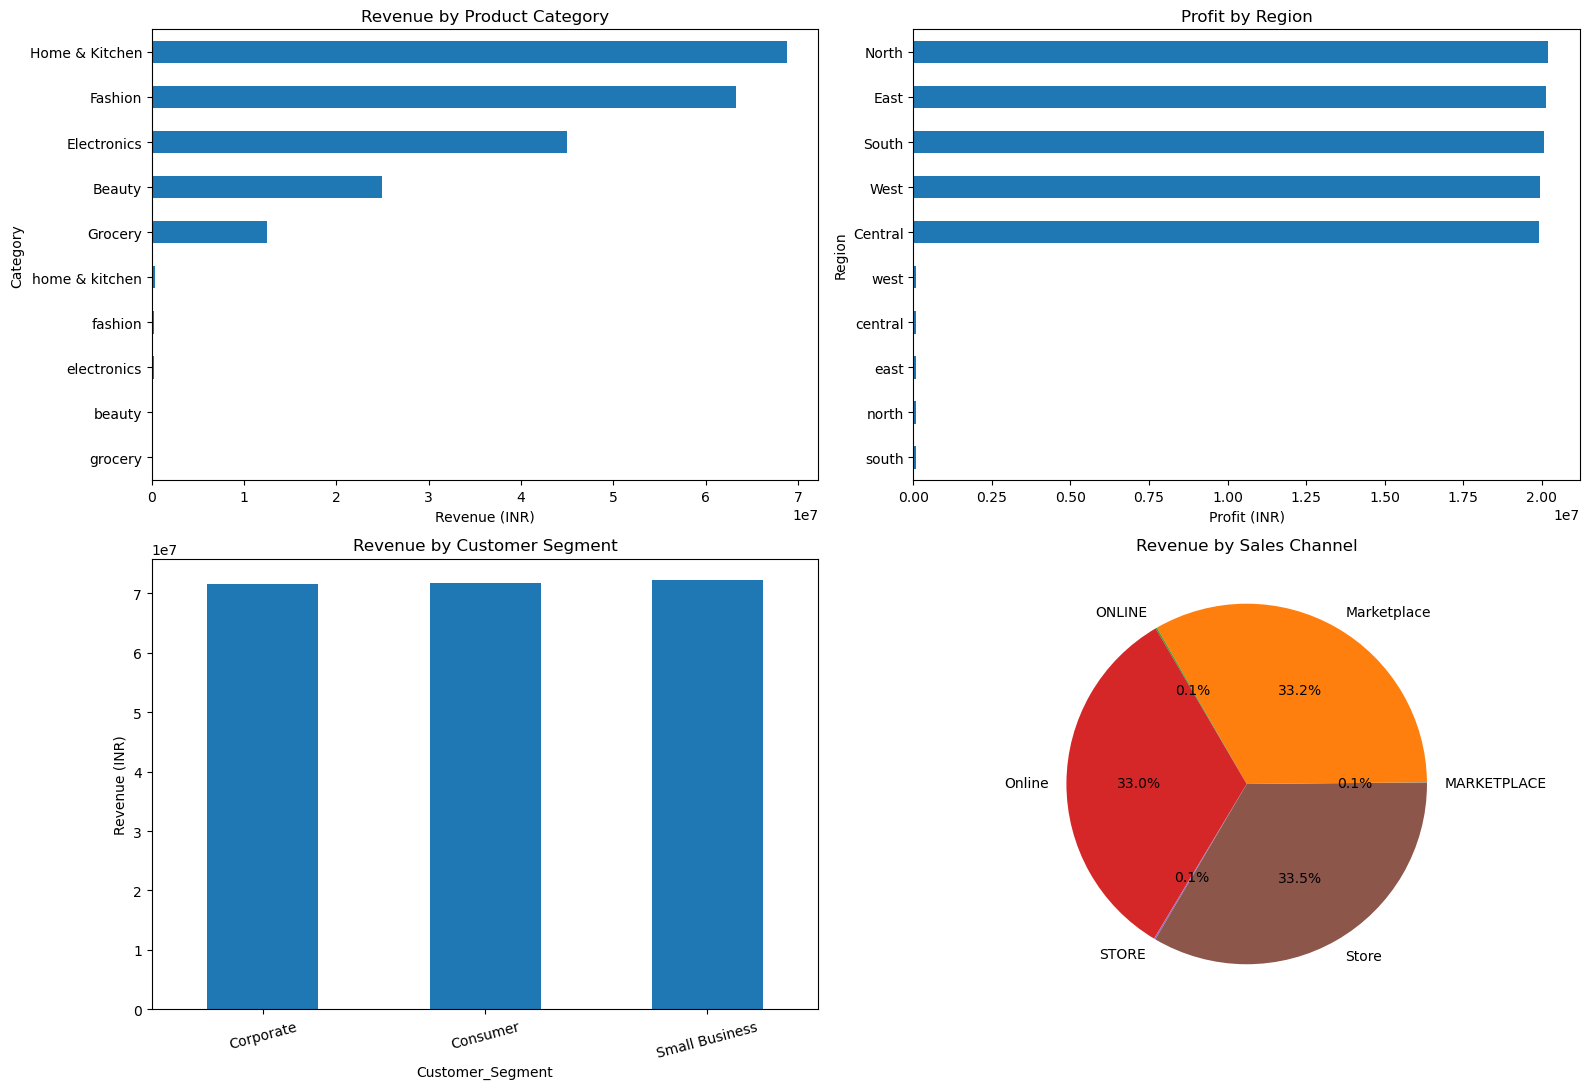

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1. Revenue by Category
category_data = df.groupby("Category")["Sales_Amount_INR"].sum().sort_values()
category_data.plot(kind="barh", ax=axes[0, 0])
axes[0, 0].set_title("Revenue by Product Category")
axes[0, 0].set_xlabel("Revenue (INR)")

# 2. Profit by Region
region_data = df.groupby("Region")["Profit_INR"].sum().sort_values()
region_data.plot(kind="barh", ax=axes[0, 1])
axes[0, 1].set_title("Profit by Region")
axes[0, 1].set_xlabel("Profit (INR)")

# 3. Revenue by Customer Segment
segment_data = df.groupby("Customer_Segment")["Sales_Amount_INR"].sum().sort_values()
segment_data.plot(kind="bar", ax=axes[1, 0])
axes[1, 0].set_title("Revenue by Customer Segment")
axes[1, 0].set_ylabel("Revenue (INR)")
axes[1, 0].tick_params(axis="x", rotation=15)

# 4. Revenue by Sales Channel
channel_data = df.groupby("Sales_Channel")["Sales_Amount_INR"].sum()
channel_data.plot(kind="pie", autopct="%1.1f%%", ax=axes[1, 1])
axes[1, 1].set_title("Revenue by Sales Channel")
axes[1, 1].set_ylabel("")

plt.tight_layout()
plt.show()

In [15]:
# Standardize text columns
text_columns = [
    "Category",
    "Region",
    "Customer_Segment",
    "Sales_Channel",
    "Product"
]

for column in text_columns:
    df[column] = df[column].astype("string").str.strip().str.title()

print("Text standardization completed!")

# Verify category labels
for column in text_columns:
    print(f"\n{column}:")
    print(df[column].value_counts())

Text standardization completed!

Category:
Category
Grocery           25286
Fashion           25130
Beauty            24840
Electronics       24780
Home & Kitchen    24718
Name: count, dtype: Int64

Region:
Region
West       25054
East       25010
South      25008
Central    24930
North      24752
Name: count, dtype: Int64

Customer_Segment:
Customer_Segment
Small Business    41771
Consumer          41635
Corporate         41348
Name: count, dtype: Int64

Sales_Channel:
Sales_Channel
Store          41672
Marketplace    41633
Online         41449
Name: count, dtype: Int64

Product:
Product
Wallet            5220
Coffee Pack       5099
Tea Pack          5087
Mixer Grinder     5078
Sunscreen         5074
Rice 5Kg          5060
Usb Cable         5055
T-Shirt           5030
Snack Box         5024
Cooking Oil       5016
Keyboard          5003
Backpack          4996
Jeans             4986
Cookware Set      4977
Face Wash         4970
Power Bank        4966
Perfume           4942
Water Bottle 

In [ ]:
# Customer Performance Analysis

In [17]:
customer_analysis = (
    df.groupby("Customer_ID")
    .agg(
        Total_Transactions=("Transaction_ID", "nunique"),
        Total_Revenue=("Sales_Amount_INR", "sum"),
        Total_Profit=("Profit_INR", "sum"),
        Total_Units=("Quantity", "sum")
    )
)

customer_analysis["Average_Order_Value"] = (
    customer_analysis["Total_Revenue"] /
    customer_analysis["Total_Transactions"]
)

customer_analysis = customer_analysis.sort_values(
    "Total_Revenue",
    ascending=False
)

print("CUSTOMER PERFORMANCE ANALYSIS")
print("--------------------------------")

print("Total Unique Customers:", df["Customer_ID"].nunique())

display(customer_analysis.head(10).round(2))

CUSTOMER PERFORMANCE ANALYSIS
--------------------------------
Total Unique Customers: 8500


,Total_Transactions,Total_Revenue,Total_Profit,Total_Units,Average_Order_Value
Customer_ID,,,,,
CUST01594,22,76473.95,32203.95,60,3476.09
CUST06545,20,74951.95,32081.95,62,3747.60
CUST08018,21,71137.30,29587.30,42,3387.49
CUST04216,23,70881.05,28366.05,68,3081.78
CUST01555,18,70749.70,29889.70,48,3930.54
CUST06797,22,70120.85,30620.85,57,3187.31
CUST05617,20,69798.75,33418.75,58,3489.94
CUST01727,26,68218.00,33068.00,60,2623.77
CUST00354,20,68138.80,30858.80,61,3406.94


In [18]:
# Product Performance Analysis

product_analysis = (
    df.groupby("Product")
    .agg(
        Total_Units_Sold=("Quantity", "sum"),
        Total_Transactions=("Transaction_ID", "nunique"),
        Total_Revenue=("Sales_Amount_INR", "sum"),
        Total_Profit=("Profit_INR", "sum")
    )
)

product_analysis["Profit_Margin"] = (
    product_analysis["Total_Profit"] /
    product_analysis["Total_Revenue"] * 100
)

product_analysis = product_analysis.sort_values(
    "Total_Revenue",
    ascending=False
)

print("TOP 10 PRODUCTS BY REVENUE")
print("---------------------------")

display(product_analysis.head(10).round(2))

TOP 10 PRODUCTS BY REVENUE
---------------------------


,Total_Units_Sold,Total_Transactions,Total_Revenue,Total_Profit,Profit_Margin
Product,,,,,
Mixer Grinder,10925,5078,29832739.30,9621489.30,32.25
Sneakers,10819,4898,25497172.05,11648852.05,45.69
Cookware Set,10852,4977,22450800.45,8126160.45,36.20
Headphones,10398,4881,14696121.05,7209561.05,49.06
Jeans,10832,4986,14266302.50,7550462.50,52.93
Power Bank,10566,4966,12959993.10,6514733.10,50.27
Backpack,10787,4996,12201443.65,6592203.65,54.03
Perfume,10633,4942,10016323.65,5444133.65,54.35
Keyboard,10735,5003,9088979.90,4472929.90,49.21


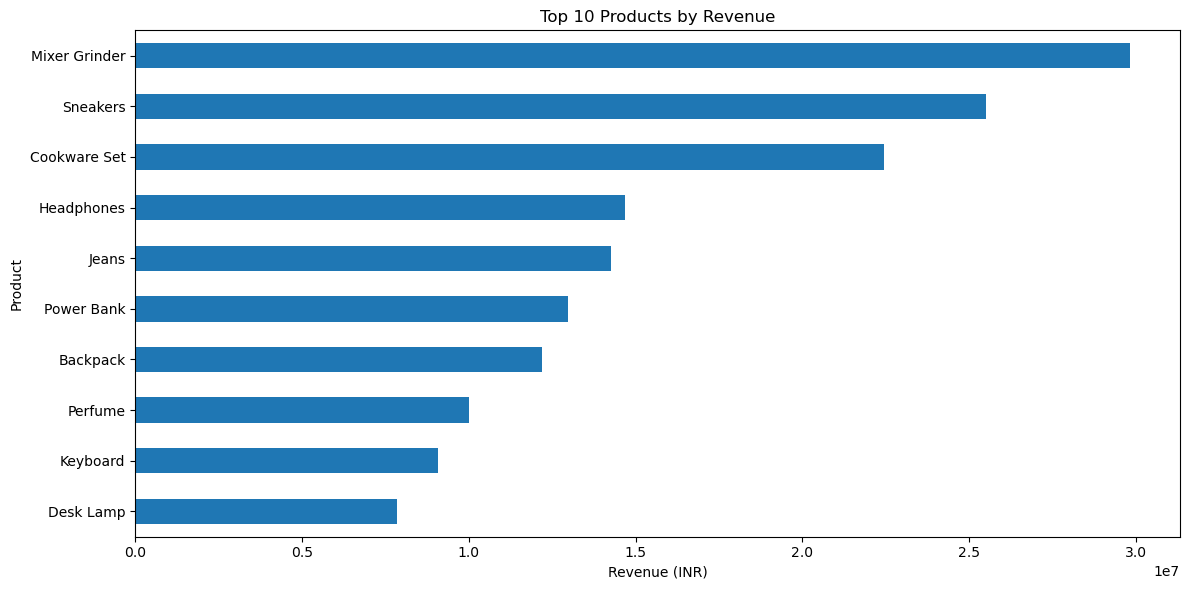

In [19]:
# Visualize top 10 products
top_products = product_analysis.head(10).sort_values(
    "Total_Revenue"
)

plt.figure(figsize=(12, 6))

top_products["Total_Revenue"].plot(kind="barh")

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue (INR)")
plt.ylabel("Product")

plt.tight_layout()
plt.show()

In [20]:
# Create discount groups

bins = [-0.001, 0, 0.05, 0.10, 0.15, 0.20]
labels = [
    "No Discount",
    "0-5%",
    "5-10%",
    "10-15%",
    "15-20%"
]

df["Discount_Group"] = pd.cut(
    df["Discount_Rate"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

print("Discount groups created successfully!")

display(df[["Discount_Rate", "Discount_Group"]].head(10))

Discount groups created successfully!


,Discount_Rate,Discount_Group
0,0.15,10-15%
1,0.15,10-15%
2,0.15,10-15%
3,0.10,5-10%
4,0.00,No Discount
5,0.00,No Discount
6,0.00,No Discount
7,0.00,No Discount
8,0.00,No Discount
9,0.00,No Discount


In [21]:
discount_analysis = (
    df.groupby("Discount_Group", observed=True)
    .agg(
        Transactions=("Transaction_ID", "nunique"),
        Units_Sold=("Quantity", "sum"),
        Revenue=("Sales_Amount_INR", "sum"),
        Cost=("Total_Cost_INR", "sum"),
        Profit=("Profit_INR", "sum")
    )
)

discount_analysis["Profit_Margin"] = (
    discount_analysis["Profit"] /
    discount_analysis["Revenue"] * 100
)

display(discount_analysis.round(2))

,Transactions,Units_Sold,Revenue,Cost,Profit,Profit_Margin
Discount_Group,,,,,,
No Discount,52404,113210,96167000.00,48218595,47948405.00,49.86
0-5%,27537,58793,47501099.15,25132650,22368449.15,47.09
5-10%,24926,53519,41145899.75,22992940,18152959.75,44.12
10-15%,13665,29478,21262635.85,12566055,8696580.85,40.90
15-20%,6217,13583,9410541.60,5915990,3494551.60,37.13


In [ ]:
# Visualize discount impact

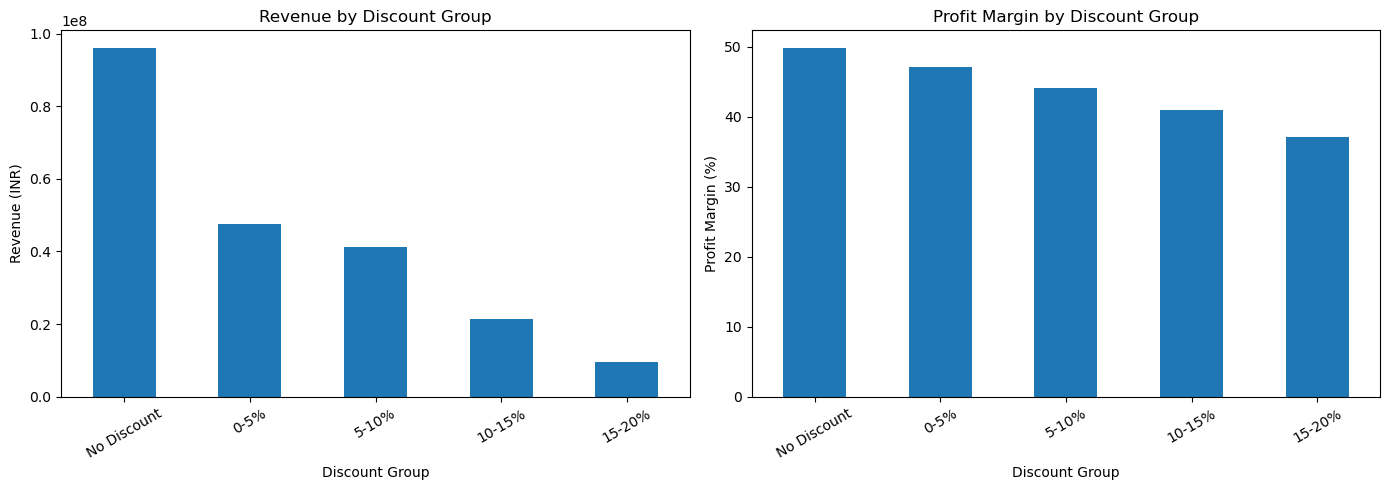

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Revenue by discount group
discount_analysis["Revenue"].plot(
    kind="bar",
    ax=axes[0]
)

axes[0].set_title("Revenue by Discount Group")
axes[0].set_xlabel("Discount Group")
axes[0].set_ylabel("Revenue (INR)")
axes[0].tick_params(axis="x", rotation=30)

# Profit margin by discount group
discount_analysis["Profit_Margin"].plot(
    kind="bar",
    ax=axes[1]
)

axes[1].set_title("Profit Margin by Discount Group")
axes[1].set_xlabel("Discount Group")
axes[1].set_ylabel("Profit Margin (%)")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

In [23]:
# Advanced Discount Performance Analysis

advanced_discount_analysis = (
    df.groupby("Discount_Group", observed=True)
    .agg(
        Transactions=("Transaction_ID", "nunique"),
        Total_Revenue=("Sales_Amount_INR", "sum"),
        Total_Profit=("Profit_INR", "sum"),
        Total_Units=("Quantity", "sum"),
        Average_Discount=("Discount_Rate", "mean")
    )
)

advanced_discount_analysis["Average_Transaction_Value"] = (
    advanced_discount_analysis["Total_Revenue"] /
    advanced_discount_analysis["Transactions"]
)

advanced_discount_analysis["Profit_Margin"] = (
    advanced_discount_analysis["Total_Profit"] /
    advanced_discount_analysis["Total_Revenue"] * 100
)

display(advanced_discount_analysis.round(2))

,Transactions,Total_Revenue,Total_Profit,Total_Units,Average_Discount,Average_Transaction_Value,Profit_Margin
Discount_Group,,,,,,,
No Discount,52404,96167000.00,47948405.00,113210,0.00,1835.11,49.86
0-5%,27537,47501099.15,22368449.15,58793,0.05,1724.99,47.09
5-10%,24926,41145899.75,18152959.75,53519,0.10,1650.72,44.12
10-15%,13665,21262635.85,8696580.85,29478,0.15,1555.99,40.90
15-20%,6217,9410541.60,3494551.60,13583,0.20,1513.68,37.13


In [ ]:
# Visualize transaction volume

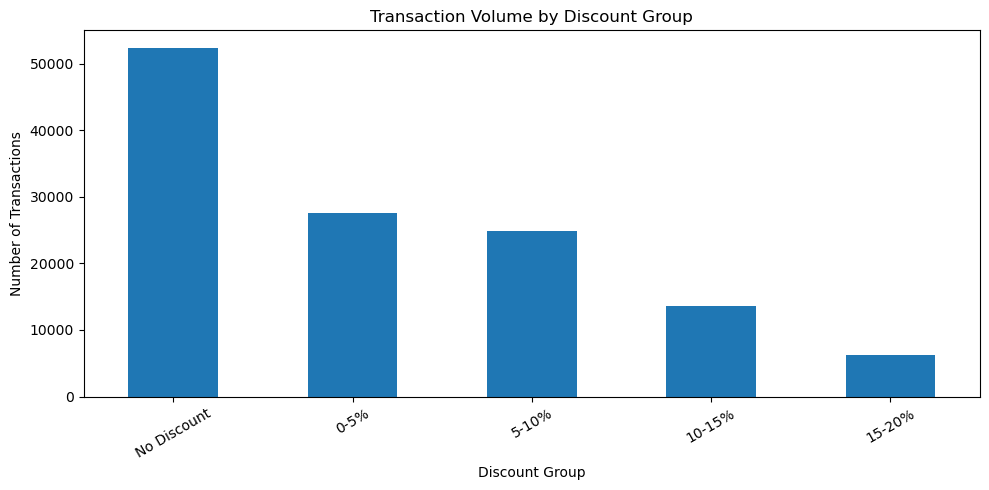

In [24]:
plt.figure(figsize=(10, 5))

advanced_discount_analysis["Transactions"].plot(
    kind="bar"
)

plt.title("Transaction Volume by Discount Group")
plt.xlabel("Discount Group")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

In [ ]:
#Compare average transaction value

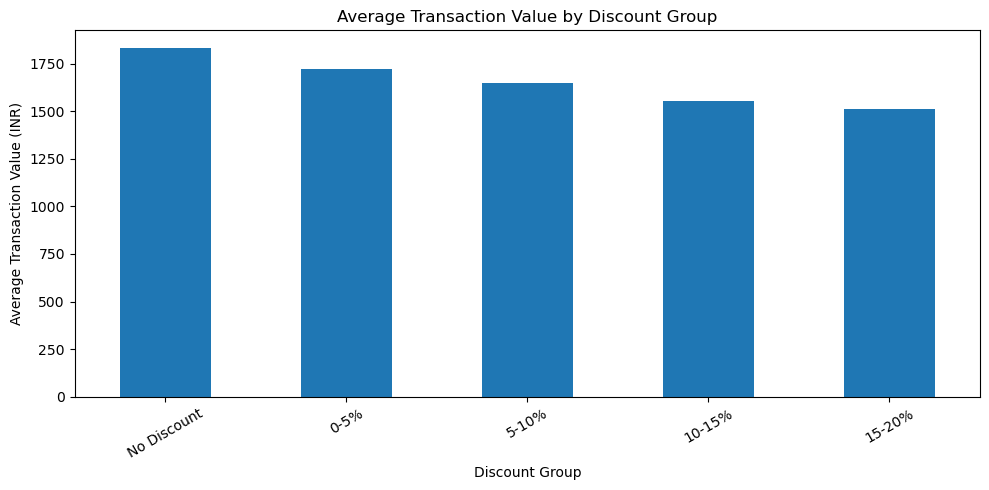

In [25]:
plt.figure(figsize=(10, 5))

advanced_discount_analysis["Average_Transaction_Value"].plot(
    kind="bar"
)

plt.title("Average Transaction Value by Discount Group")
plt.xlabel("Discount Group")
plt.ylabel("Average Transaction Value (INR)")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

In [27]:
# Export the standardized dataset for MySQL

output_path = "../Dataset/retail_sales_python_ready.csv"

df.to_csv(
    output_path,
    index=False,
    encoding="utf-8-sig"
)

print("Dataset exported successfully!")
print("File:", output_path)
print("Total Records:", len(df))
print("Total Columns:", len(df.columns))

Dataset exported successfully!
File: ../Dataset/retail_sales_python_ready.csv
Total Records: 124754
Total Columns: 20
